# ECG Waveform and R-Peak Extraction
Extract the **green ECG trace** in a Terason Doppler screenshot, return its **image y-coordinates**, and conservatively identify strong **R-peak candidates**. The analysis is in pixel coordinates only (no OCR or physiological calibration).

# Setup

In [46]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks, medfilt


In [47]:
data_dir = Path.cwd().resolve().parents[2] / "data" / "ecg"  # modules/ecg/scratch -> repo root
ecg_img_path = data_dir / "input" / "ecg_wave.png"
output_dir = data_dir / "output"


# Define Regions of Interest

In [48]:
# Coordinate conventions match test_ocr and the waveform extraction notebook.
# Reference resolution: 1024 x 768; ROI: (x0, y0, x1, y1).
# The selected region covers the green ECG line, not the white Doppler signal.
REF_W, REF_H = 1024, 768
ROIS = {
    "ecg": (80, 589, 716, 643),
}

# Green detection: require green dominance rather than overall brightness.
MIN_GREEN = 45
GREEN_MINUS_RED = 22
GREEN_MINUS_BLUE = 16

# Conservative safeguards against spurious peak detections.
MIN_TRACE_COVERAGE = 0.70     # fraction of columns containing ECG-colored pixels
MIN_PRESENT_PEAKS = 2        # avoid declaring an ECG from one isolated green spike
MIN_R_PROMINENCE = 18        # minimum peak height relative to nearby ECG (pixels)
MIN_R_DISTANCE = 75         # minimum separation on THIS 1024px reference image
MIN_R_WIDTH, MAX_R_WIDTH = 1.5, 18   # narrow QRS-like peak in pixels
MEDIAN_KERNEL = 3           # small filtering of y-series for detecting peaks only


In [49]:
def scaled_roi(img, name):
    h, w = img.shape[:2]
    x0, y0, x1, y1 = ROIS[name]
    sx, sy = w / REF_W, h / REF_H
    return (int(round(x0 * sx)), int(round(y0 * sy)),
            int(round(x1 * sx)), int(round(y1 * sy)))


def crop(img, name):
    x0, y0, x1, y1 = scaled_roi(img, name)
    return img[y0:y1, x0:x1], (x0, y0)


# Extract ECG Waveform

In [ ]:
def extract_ecg(img):
    """Return ECG mask and one y value per x, in FULL-IMAGE pixel coordinates.

    The green trace may be 1-3 pixels thick, so its per-column min y is
    used instead of choosing the topmost pixel. Missing columns are interpolated
    ONLY when a sufficiently continuous green trace is present.
    """
    roi, (x0, y0) = crop(img, "ecg")
    if roi.size == 0:
        raise ValueError("ECG ROI is empty; check ROIS and image dimensions")

    b, g, r = [channel.astype(np.int16) for channel in cv2.split(roi)]
    green = ((g >= MIN_GREEN) &
             ((g - r) >= GREEN_MINUS_RED) &
             ((g - b) >= GREEN_MINUS_BLUE))
    mask = (green.astype(np.uint8) * 255)

    width = roi.shape[1]
    x_coords = x0 + np.arange(width)
    y_raw = np.full(width, np.nan, dtype=float)
    for x in range(width):
        rows = np.flatnonzero(green[:, x])
        if rows.size:
            y_raw[x] = float(np.min(rows) + y0)

    valid = np.isfinite(y_raw)
    coverage = valid.mean()
    # No ECG trace -> never fabricate a waveform by interpolating the background.
    if coverage < MIN_TRACE_COVERAGE:
        y = np.full(width, np.nan, dtype=float)
        ecg_present = False
    else:
        y = np.interp(np.arange(width), np.flatnonzero(valid), y_raw[valid])
        ecg_present = True

    coords = np.column_stack((x_coords, y))
    return mask, coords, y, valid, float(coverage), ecg_present


# Detect R-Peak Candidates

In [51]:
def detect_r_peaks(envelope_y, ecg_present, image_width):
    """Return indices of strong upward ECG spikes (small y = high on screen).

    Detection must satisfy prominence, width, spacing and >=2-peak safeguards.
    These are image-shape candidates; they are not a diagnostic ECG assessment.
    """
    if not ecg_present or not np.all(np.isfinite(envelope_y)):
        return np.array([], dtype=int)

    scale = image_width / REF_W
    # Three-point median is used ONLY for detection; exported coordinates remain raw.
    smooth = medfilt(envelope_y, kernel_size=MEDIAN_KERNEL)
    upward = np.median(smooth) - smooth
    peaks, properties = find_peaks(
        upward,
        prominence=MIN_R_PROMINENCE * scale,
        distance=max(1, int(MIN_R_DISTANCE * scale)),
        width=(max(1, MIN_R_WIDTH * scale), max(2, MAX_R_WIDTH * scale)),
    )

    # Refine each detected peak using the unsmoothed ECG coordinates
    refined_peaks = []

    for peak in peaks:
        left = max(0, peak - 5)
        right = min(len(envelope_y), peak + 6)

        local_y = envelope_y[left:right]

        if np.any(np.isfinite(local_y)):
            refined_peak = left + np.nanargmin(local_y)
            refined_peaks.append(refined_peak)

    return np.array(refined_peaks, dtype=int)


# Main Function

In [52]:
def main(input_path, output_path):
    """Extract green ECG y-coordinates and conservatively detect R peaks.

    Parameters
    ----------
    input_path : str or Path
        Screenshot (e.g. 'data/ecg/input/ecg_wave.png').
    output_path : str or Path
        Folder for CSV coordinate files and output PNGs.

    Returns
    -------
    dict containing ecg_y (W,), ecg_coords (W,2), ecg_mask,
    valid_columns, ecg_present, r_peaks_x, r_peaks_y, and coverage.
    All x and y values refer to the FULL screenshot (origin = upper left).
    y is NaN if the ECG is not sufficiently detected.
    """
    input_path, output_path = Path(input_path), Path(output_path)
    img = cv2.imread(str(input_path))
    if img is None:
        raise FileNotFoundError(f"Could not read image: {input_path}")

    mask, coords, ecg_y, valid, coverage, present = extract_ecg(img)
    peaks = detect_r_peaks(ecg_y, present, image_width=img.shape[1])
    r_peaks_x = coords[peaks, 0].astype(int)
    r_peaks_y = ecg_y[peaks]

    output_path.mkdir(parents=True, exist_ok=True)
    np.savetxt(output_path / "ecg_y.csv", ecg_y, delimiter=",",
               header="y_pixel", comments="", fmt="%.3f")
    np.savetxt(output_path / "ecg_coordinates.csv", coords, delimiter=",",
               header="x_pixel,y_pixel", comments="", fmt="%.3f")
    np.savetxt(output_path / "r_peaks.csv",
               np.column_stack((r_peaks_x, r_peaks_y)).reshape((-1, 2)),
               delimiter=",", header="x_pixel,y_pixel", comments="", fmt="%.3f")
    cv2.imwrite(str(output_path / "ecg_mask.png"), mask)

    x0, y0, x1, y1 = scaled_roi(img, "ecg")
    # Full-image overlay, zoomed to the ECG region for visual validation.
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    if present:
        ax.plot(coords[:, 0], ecg_y, c="cyan", linewidth=1.2,
                label="Extracted ECG")
        if len(peaks):
            ax.scatter(r_peaks_x, r_peaks_y, c="red", s=10, marker="o",
                       edgecolors="white", linewidths=0.6, zorder=4,
                       label="R-peak candidates")
    else:
        ax.text(0.5, 0.5, "No reliable ECG signal detected",
                transform=ax.transAxes, ha="center", va="center", color="red")
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)  # original image pixel orientation
    ax.set_xlabel("Image x (pixels)")
    ax.set_ylabel("Image y (pixels)")
    ax.set_title("ECG extraction over original screenshot")
    if present:
        ax.legend(loc="upper left")
    fig.tight_layout()
    fig.savefig(output_path / "ecg_overlay.png", dpi=160)
    plt.show()
    plt.close(fig)

    # Standalone coordinate graph; same pixel coordinate convention.
    fig, ax = plt.subplots(figsize=(13, 4))
    if present:
        ax.plot(coords[:, 0], ecg_y, c="green", linewidth=1.4,
                label="ECG y-coordinates")
        if len(peaks):
            ax.scatter(r_peaks_x, r_peaks_y, color="red", s=10,
                       zorder=4, label="R-peak candidates")
        ax.legend()
    else:
        ax.text(0.5, 0.5, "No reliable ECG signal detected",
                transform=ax.transAxes, ha="center", va="center")
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)
    ax.set_xlabel("Image x (pixels)")
    ax.set_ylabel("Image y (pixels)")
    ax.set_title("Extracted ECG waveform (image coordinates)")
    ax.grid(alpha=0.15)
    fig.tight_layout()
    fig.savefig(output_path / "ecg_graph.png", dpi=160)
    plt.show()
    plt.close(fig)

    return {
        "ecg_mask": mask,
        "ecg_coords": coords,
        "ecg_y": ecg_y,
        "valid_columns": valid,
        "ecg_present": present,
        "r_peaks_x": r_peaks_x,
        "r_peaks_y": r_peaks_y,
        "coverage": coverage,
    }


# Test ECG Extraction

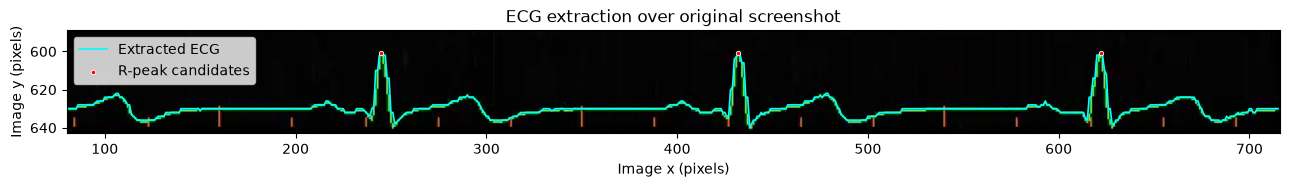

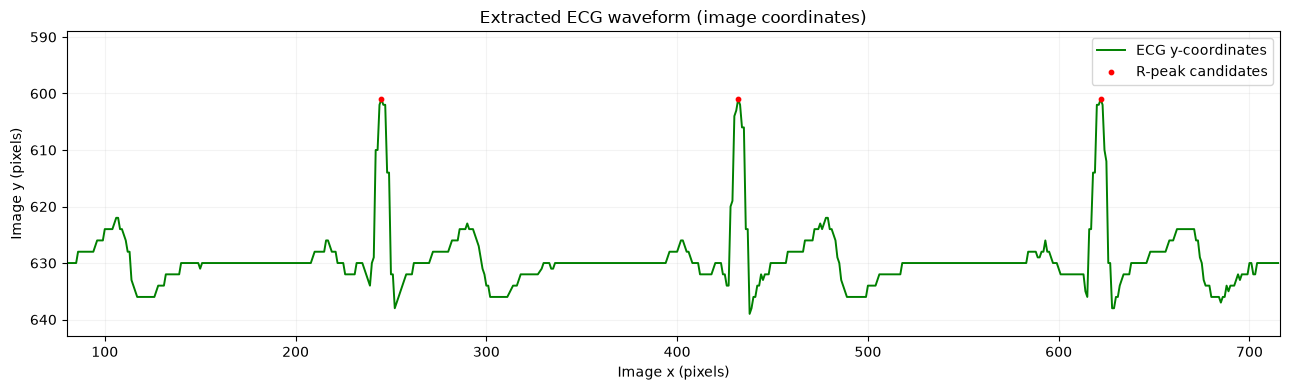

ECG present: True
Green trace column coverage: 98.4%
R-peak candidate x-coordinates: [245, 432, 622]
First 10 ECG y-coordinates: [630. 630. 630. 630. 630. 630. 628. 628. 628. 628.]


In [53]:
results = main(
    input_path=ecg_img_path,
    output_path=output_dir,
)
print("ECG present:", results["ecg_present"])
print(f"Green trace column coverage: {results['coverage']:.1%}")
print("R-peak candidate x-coordinates:", results["r_peaks_x"].tolist())
print("First 10 ECG y-coordinates:", results["ecg_y"][:10])


# Visualize ECG Mask

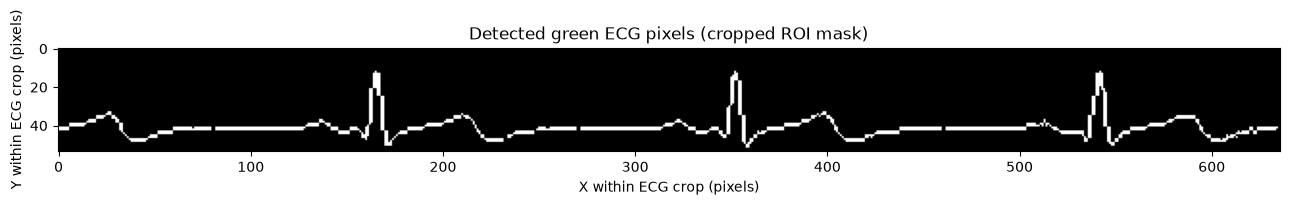

In [54]:
plt.figure(figsize=(13, 3))
plt.imshow(results["ecg_mask"], cmap="gray")
plt.title("Detected green ECG pixels (cropped ROI mask)")
plt.xlabel("X within ECG crop (pixels)")
plt.ylabel("Y within ECG crop (pixels)")
plt.tight_layout()
plt.show()


# END